### LangGraph核心组件：工具调用

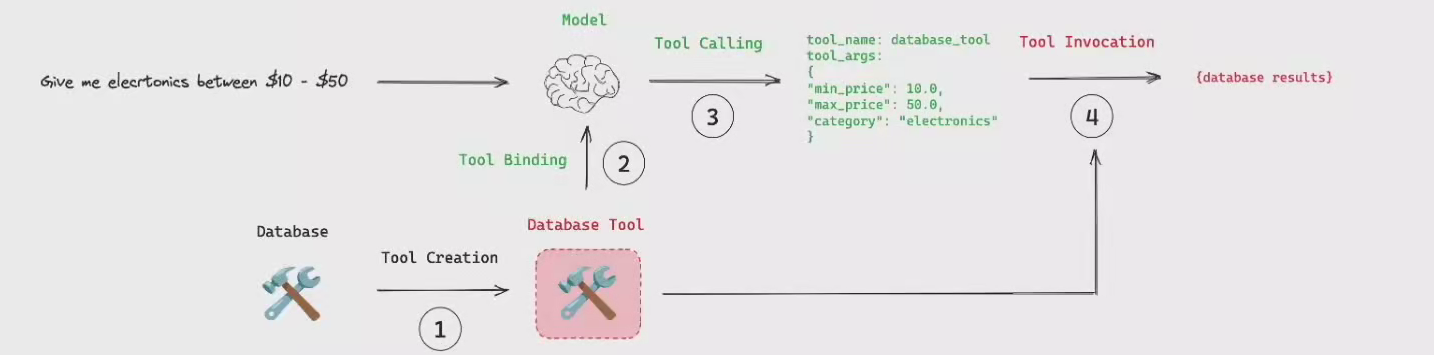
- 第一步：使用@tool修饰符创建工具
- 第二步：绑定工具到模型
- 第三步：工具调用-将自然语言转为正确的参数
- 第四步：工具执行-将工具执行并将结果传递给下一步

***
- 工具定义
- 工具绑定
- 工具调用
- 工具执行

#### 工具定义
***

In [17]:
from langchain_core.messages import AIMessage
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode
from langgraph.graph import StateGraph, MessagesState, START

# 1. 定义工具
@tool
def get_weather(location: str):
    """调用此函数获取当前天气。"""
    if location.lower() in ["北京", "深圳"]:
        return "现在是20度，有雾。"
    else:
        return "现在是10度，晴朗"

tools = [get_weather]
tool_node = ToolNode(tools)

# 2. 构造模拟的 AI 消息
message_with_single_tool_call = AIMessage(
    content="",
    tool_calls=[{
        "name": "get_weather",
        "args": {"location": "北京"},
        "id": "call_abc123",
        "type": "tool_call"
    }]
)

# ==========================================
# 🌟 核心修改：构建一个极简图来包装 ToolNode
# ==========================================
builder = StateGraph(MessagesState)
builder.add_node("tools", tool_node)
builder.add_edge(START, "tools")

# 编译图 (这里不需要 checkpointer，因为只是单次测试)
app = builder.compile()

# 3. 通过图来调用 ToolNode
print("正在通过 StateGraph 调用 ToolNode...")
result = app.invoke({"messages": [message_with_single_tool_call]})

# 打印结果
print("\n工具执行结果:")
for msg in result["messages"]:
    # 跳过最初的 AIMessage，只打印 ToolMessage
    if msg.type == "tool":
        print(f"- 工具名: {msg.name}, 结果: {msg.content}")

正在通过 StateGraph 调用 ToolNode...

工具执行结果:
- 工具名: get_weather, 结果: 现在是20度，有雾。


langgraph提供了低层面的封装，可以直接手动执行工具

In [16]:
# 直接调用工具函数本身，绕过 ToolNode
print("直接调用工具函数:")
result = get_weather.invoke({"location": "北京"})
print(f"结果: {result}")

直接调用工具函数:
结果: 现在是20度，有雾。


In [25]:
from langchain_core.messages import AIMessage, HumanMessage, BaseMessage
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode
from langgraph.graph import StateGraph, START, END, MessagesState

# 1. 定义工具
@tool
def get_weather(location: str):
    """调用此函数获取当前天气。"""
    if location.lower() in ["北京", "深圳"]:
        return "现在是20度，有雾。"
    else:
        return "现在是10度，晴朗"

@tool
def get_coldest_cities():
    """获取最冷的城市列表"""
    return "哈尔滨, 北京"

tools = [get_weather, get_coldest_cities]

# 2. 构建一个极简的 StateGraph 来包装 ToolNode
# 这样可以让 LangGraph 的内部调度器去处理 config，绕过独立调用的 Bug
tool_node = ToolNode(tools)

# 定义一个dummy节点，仅仅为了把消息传给 tool_node
def dummy_agent(state: MessagesState):
    # 模拟大模型返回了一个工具调用
    return {
        "messages": [
            AIMessage(
                content="",
                tool_calls=[{
                    "name": "get_weather",
                    "args": {"location": "北京"},
                    "id": "tool_call_id_123",
                    "type": "tool_call"
                }]
            )
        ]
    }

# 构建图
workflow = StateGraph(MessagesState)
workflow.add_node("agent", dummy_agent)
workflow.add_node("action", tool_node)

workflow.add_edge(START, "agent")
workflow.add_edge("agent", "action")
workflow.add_edge("action", END)

# 编译图 (不需要 checkpointer 也可以跑)
app = workflow.compile()

# 3. 运行图
print("--- 开始执行 StateGraph ---")
# 传入一个初始消息触发 dummy_agent
inputs = {"messages": [HumanMessage(content="帮我查天气")]}

for chunk in app.stream(inputs, stream_mode="values"):
    # 打印最后一条消息的内容
    last_msg = chunk["messages"][-1]
    if hasattr(last_msg, "content") and last_msg.content:
        print(f"工具执行结果: {last_msg.content}")

--- 开始执行 StateGraph ---
工具执行结果: 帮我查天气
工具执行结果: 现在是20度，有雾。


In [49]:
from langchain_core.messages import AIMessage
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode

# 1. 定义工具
@tool
def get_weather(location: str):
    """调用此函数获取当前天气。"""
    if location.lower() in ["北京", "深圳"]:
        return "现在是20度，有雾。"
    else:
        return "现在是10度，晴朗"

@tool
def get_coldest_cities():
    """获取最冷的城市列表"""
    return "哈尔滨, 北京"

# 2. 初始化 ToolNode
tools = [get_weather, get_coldest_cities]
tool_node = ToolNode(tools)

# 3. 构造 AIMessage
message_with_single_tool_call = AIMessage(
    content="",
    tool_calls=[{
        "name": "get_weather",
        "args": {"location": "北京"},
        "id": "tool_call_id_123",
        "type": "tool_call"
    }]
)

# 4. 🌟 暴力修复：强行在 config 中塞入 'N/A' 键来欺骗校验器
hack_config = {
    "configurable": {"thread_id": "test-thread-1"},
    "N/A": None  # 👈 专门针对 Python 3.14 Bug 的强行注入
}

# 🌟 构建极简图
builder = StateGraph(MessagesState)
builder.add_node("tools", tool_node)
builder.add_edge(START, "tools")
app = builder.compile()

# 🌟 通过图来调用，让图自动处理 config
result = app.invoke({"messages": [message_with_single_tool_call]})
print(result["messages"][-1].content)

现在是20度，有雾。


#### 绑定工具
***

In [50]:
from langchain_deepseek import ChatDeepSeek
import os
from langgraph.graph import StateGraph, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv()

model_with_tools = ChatDeepSeek(
    model = "deepseek-ai/DeepSeek-V4-Flash",
    temperature=0,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
).bind_tools(tools)

In [51]:
model_with_tools.invoke("深圳的天气如何？").tool_calls

[{'name': 'get_weather',
  'args': {'location': '深圳'},
  'id': '01a1808af6f9867b9252746cdfb80cbd',
  'type': 'tool_call'}]

执行工具，返回ToolMessage

In [52]:
# 1. 让模型生成 tool_calls
ai_message = model_with_tools.invoke("深圳的天气如何？")
print("模型决定的调用:", ai_message.tool_calls)

# 2. 手动提取参数并直接调用工具函数（完美绕过 ToolNode 的底层 Bug）
tool_call = ai_message.tool_calls[0]
tool_name = tool_call['name']
tool_args = tool_call['args']

# 找到对应的工具函数
target_tool = next((t for t in tools if t.name == tool_name), None)

if target_tool:
    # 直接 invoke 工具函数本身，不需要 ToolNode
    result = target_tool.invoke(tool_args)
    print("\n工具执行结果:", result)
else:
    print("未找到对应工具")

模型决定的调用: [{'name': 'get_weather', 'args': {'location': '深圳'}, 'id': '01a1808b0818be51a95ae65686564498', 'type': 'tool_call'}]

工具执行结果: 现在是20度，有雾。


在 ReAct 智能体中执行
***

In [45]:
from typing import Literal

from langgraph.graph import StateGraph, MessagesState, START, END

def should_continue(state: MessagesState):
    messages = state["messages"]
    last_message = messages[-1]
    if last_message.tool_calls:
        return "tools"
    return END

def call_model(state: MessagesState):
    messages = state["messages"]
    response = model_with_tools.invoke(messages)
    return {"messages": [response]}

workflow = StateGraph(MessagesState)

workflow.add_node("agent", call_model)
workflow.add_node("tools", tool_node) # Add the tool node to the graph

workflow.add_edge(START, "agent")
workflow.add_conditional_edges("agent", should_continue, ["tools", END])
workflow.add_edge("tools", "agent")

app = workflow.compile()

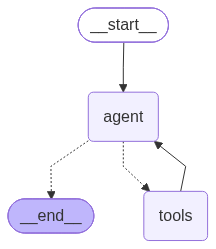

In [46]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [47]:
for chunk in app.stream(
    {"messages": [("human", "深圳的天气如何？")]},
    stream_mode="values"
):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

深圳的天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (01a1807c64369b163adb4633e94cde3b)
 Call ID: 01a1807c64369b163adb4633e94cde3b
  Args:
    location: 深圳
================================= Tool Message =================================
Name: get_weather

现在是20度，有雾。
================================== Ai Message ==================================

深圳当前天气为 **20摄氏度**，有雾。🌫️

出门请注意带好保暖衣物，同时雾天能见度可能较低，出行时请留意交通安全。如果需要更多天气信息，随时告诉我！


In [48]:
for chunk in app.stream(
    {"messages": [("human", "天气最冷的城市如何？")]},
    stream_mode="values"
):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

天气最冷的城市如何？
================================== Ai Message ==================================
Tool Calls:
  get_coldest_cities (01a1807c8395c3b08fa8dfd96b4c9f5e)
 Call ID: 01a1807c8395c3b08fa8dfd96b4c9f5e
  Args:
================================= Tool Message =================================
Name: get_coldest_cities

哈尔滨, 北京
================================== Ai Message ==================================
Tool Calls:
  get_weather (01a1807c886f2c2e536b9f332ce31a3c)
 Call ID: 01a1807c886f2c2e536b9f332ce31a3c
  Args:
    location: 哈尔滨
  get_weather (01a1807c886f2c2e536b9f332ce31a3d)
 Call ID: 01a1807c886f2c2e536b9f332ce31a3d
  Args:
    location: 北京
================================= Tool Message =================================
Name: get_weather

现在是20度，有雾。
================================== Ai Message ==================================

根据查询结果，目前最冷的两个城市情况如下：

**哈尔滨** 🌨️
- 温度：**10度**
- 天气：晴朗

**北京** 🌫️
- 温度：